# Plan

CropQuery — Ensemble Integration Plan
Goal: Replace the single ResNet50 vision backbone with a 3-model ensemble (ResNet50 + EfficientNet-B3 + DenseNet121) + FAISS k-NN, while keeping the existing RAG → LLaVA → IndicTrans2 advisory pipeline intact.

Architecture:
Image Input
    ↓
┌─────────────────────────────────┐
│  Ensemble (cuda:0)              │
│  ResNet50 + EffNet + DenseNet   │
│  → averaged softmax probs       │
│                                 │
│  FAISS k-NN (CPU)               │
│  → vote-based label             │
└────────────┬────────────────────┘
             ↓
     Combiner: conf ≥ 85%?
     YES → ensemble label
     NO  → k-NN label
             ↓
     RAG Retrieval (ChromaDB)
             ↓
     LLaVA-Next 7B 4-bit (cuda:1)
             ↓
     IndicTrans2 (cuda:1)
             ↓
     Gradio UI

# Dependencies

In [1]:
!pip install -q transformers accelerate bitsandbytes chromadb \
    sentence-transformers datasets gradio torch torchvision \
    Pillow faiss-cpu IndicTransToolkit

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.7/60.7 MB 32.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.3/23.3 MB 74.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 56.8 MB/s eta 0:00:0000:01m00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 546.3/546.3 kB 28.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 278.2/278.2 kB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 112.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 59.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 4.1 MB/s eta 0:00:0

In [2]:
import os
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
os.makedirs("/kaggle/working/cropquery/", exist_ok=True)
print("HF_TOKEN set. Working dir ready.")

HF_TOKEN set. Working dir ready.


# Config

In [3]:
%%writefile /kaggle/working/cropquery/config.py
import os

BASE_DIR = os.path.dirname(os.path.abspath(__file__))
CHROMA_DIR = "/kaggle/working/chroma_db"

# ── Device assignment ──────────────────────────────────────────────────────
BACKBONE_DEVICE = "cuda:0"
LLAVA_DEVICE    = "cuda:1"

# ── Ensemble checkpoint paths ──────────────────────────────────────────────
RUNS_DIR          = "/kaggle/input/datasets/vitthaljauhari2/cropquerydataset"
RESNET_CKPT       = os.path.join(RUNS_DIR, "resnet50_best.pth")
EFFICIENTNET_CKPT = os.path.join(RUNS_DIR, "efficientnet_best.pth")
DENSENET_CKPT     = os.path.join(RUNS_DIR, "densenet_best.pth")

# ── FAISS feature bank ─────────────────────────────────────────────────────
BANK_PREFIX   = "/kaggle/input/datasets/vitthaljauhari2/cropquerydataset/feature_bank"
BANK_FEATURES = f"{BANK_PREFIX}_features.npy"
BANK_LABELS   = f"{BANK_PREFIX}_labels.npy"

# ── Class map ──────────────────────────────────────────────────────────────
CLASS_NAMES_PATH = os.path.join(BASE_DIR, "class_names.json")
NUM_CLASSES      = 64

# ── Vision / combiner ──────────────────────────────────────────────────────
IMG_SIZE        = 224
CONFIDENCE_GATE = 80.0
KNN_K           = 7
TOP_K           = 3

# ── Embedding / RAG ────────────────────────────────────────────────────────
EMBED_MODEL      = "sentence-transformers/all-MiniLM-L6-v2"
COLLECTION_NAME  = "cropquery_knowledge"
TOP_CHUNKS       = 5
MIN_CROP_CHUNKS  = 2
TOP_K_AGROBENCH  = 3
TOP_K_KISAN      = 2

# ── LLaVA ─────────────────────────────────────────────────────────────────
LLAVA_MODEL_ID   = "llava-hf/llava-v1.6-mistral-7b-hf"
LLAVA_MAX_TOKENS = 512
LOAD_IN_4BIT     = True

# ── IndicTrans2 ────────────────────────────────────────────────────────────
INDICTRANS_MODEL = "ai4bharat/indictrans2-en-indic-1B"
DEFAULT_LANGUAGE = "hin_Deva"
LANGUAGE_CODES = {
    "Hindi":     "hin_Deva",
    "Marathi":   "mar_Deva",
    "Bengali":   "ben_Beng",
    "Telugu":    "tel_Telu",
    "Tamil":     "tam_Taml",
    "Kannada":   "kan_Knda",
    "Gujarati":  "guj_Gujr",
    "Punjabi":   "pan_Guru",
    "Odia":      "ory_Orya",
    "Malayalam": "mal_Mlym",
    "English":   None,
}

# ── Weather / Location ─────────────────────────────────────────────────────
WEATHER_API_URL = "https://api.open-meteo.com/v1/forecast"
GEOCODE_API_URL = "https://nominatim.openstreetmap.org/reverse"

# ── HuggingFace dataset ────────────────────────────────────────────────────
HF_KISAN_DATASET = "Franklin01/Dataset_prep01"

Overwriting /kaggle/working/cropquery/config.py


# Vision.py

In [4]:
%%writefile /kaggle/working/cropquery/vision.py

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models
from PIL import Image
from torchvision import transforms
from typing import List, Tuple, Optional, Dict
import json

from .config import IMG_SIZE, CLASS_NAMES_PATH


def remap_state_dict(state_dict: dict) -> dict:
    """
    Convert keys from training format (encoder.*, head.*) to inference format (features.*, classifier.*)
    Also removes 'num_batches_tracked' keys which are not needed.
    """
    new_sd = {}
    for k, v in state_dict.items():
        if k.endswith('num_batches_tracked'):
            continue
        if k.startswith('encoder.'):
            new_k = 'features.' + k[8:]
        elif k.startswith('head.'):
            new_k = 'classifier.' + k[5:]
        else:
            new_k = k
        new_sd[new_k] = v
    return new_sd


class ResNet50Backbone(nn.Module):
    """ResNet50 backbone with feature extractor and classifier."""
    def __init__(self, n_classes: int = 64):
        super().__init__()
        base = models.resnet50(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(2048, n_classes)
        )

    def forward(self, x):
        f = self.features(x).flatten(1)
        return self.classifier(f)

    def extract_features(self, x):
        return self.features(x).flatten(1)


class EfficientNetB3Backbone(nn.Module):
    """EfficientNet-B3 backbone."""
    def __init__(self, n_classes: int = 64):
        super().__init__()
        base = models.efficientnet_b3(weights=None)
        self.features = base.features
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(1536, n_classes)
        )

    def forward(self, x):
        f = self.features(x)
        # FIX: Apply Global Average Pooling before flattening
        f = F.adaptive_avg_pool2d(f, 1).flatten(1)
        return self.classifier(f)

    def extract_features(self, x):
        f = self.features(x)
        return F.adaptive_avg_pool2d(f, 1).flatten(1)


class DenseNet121Backbone(nn.Module):
    """DenseNet-121 backbone."""
    def __init__(self, n_classes: int = 64):
        super().__init__()
        base = models.densenet121(weights=None)
        self.features = base.features
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(1024, n_classes)
        )

    def forward(self, x):
        f = self.features(x)
        # FIX: DenseNet requires a ReLU activation, then GAP before flattening
        f = F.relu(f, inplace=True)
        f = F.adaptive_avg_pool2d(f, 1).flatten(1)
        return self.classifier(f)

    def extract_features(self, x):
        f = self.features(x)
        f = F.relu(f, inplace=True)
        return F.adaptive_avg_pool2d(f, 1).flatten(1)

class FAISSRetriever:
    """CPU-based FAISS k-NN retriever using a pre-built feature bank."""

    def __init__(self, features_path: str, labels_path: str, k: int = 7):
        import faiss
        self.k = k
        features = np.load(features_path).astype(np.float32)
        self.labels = np.load(labels_path)
        # L2-normalise for cosine similarity
        faiss.normalize_L2(features)
        self.index = faiss.IndexFlatIP(features.shape[1])
        self.index.add(features)
        print(f"[FAISS] Loaded index: {features.shape[0]} vectors, dim={features.shape[1]}, k={k}")

    def query(self, feature_vec: np.ndarray) -> str:
        """Return majority-vote class from k nearest neighbours."""
        import faiss
        vec = feature_vec.astype(np.float32).reshape(1, -1)
        faiss.normalize_L2(vec)
        _, indices = self.index.search(vec, self.k)
        neighbour_labels = self.labels[indices[0]]
        # Majority vote
        values, counts = np.unique(neighbour_labels, return_counts=True)
        return values[counts.argmax()]
        

class CropVisionModel:
    """
    Multi‑backbone vision model for crop disease classification.
    Loads ResNet50, EfficientNet‑B3 and DenseNet‑121 from your checkpoints.
    """

    def __init__(self, device: str = "cuda"):
        self.device = torch.device(device if torch.cuda.is_available() else "cpu")
        
        # Load class names
        with open(CLASS_NAMES_PATH, 'r') as f:
            self.class_names = json.load(f)
        self.n_classes = len(self.class_names)

        # Define checkpoint paths – adjust if necessary
        base_ckpt = "/kaggle/input/datasets/vitthaljauhari2/cropquerydataset"
        checkpoints = {
            "resnet50":      f"{base_ckpt}/resnet50_best.pth",
            "efficientnet":  f"{base_ckpt}/efficientnet_best.pth",
            "densenet":      f"{base_ckpt}/densenet_best.pth",
        }

        self.backbones: Dict[str, nn.Module] = {}
        for name, path in checkpoints.items():
            if name == "resnet50":
                model = ResNet50Backbone(self.n_classes)
            elif name == "efficientnet":
                model = EfficientNetB3Backbone(self.n_classes)
            elif name == "densenet":
                model = DenseNet121Backbone(self.n_classes)
            else:
                continue

            ckpt = torch.load(path, map_location="cpu")
            state_dict = ckpt.get("model_state_dict", ckpt)  # some checkpoints have direct dict
            remapped = remap_state_dict(state_dict)
            # strict=False ignores any remaining mismatches (e.g., missing `num_batches_tracked`)
            model.load_state_dict(remapped, strict=False)
            model.to(self.device)
            model.eval()
            self.backbones[name] = model

        print(f"[Vision] Loaded {len(self.backbones)} backbones (ResNet50, EfficientNet, DenseNet)")
        
        # Load FAISS feature bank
        from .config import BANK_FEATURES, BANK_LABELS, KNN_K
        try:
            self.faiss = FAISSRetriever(BANK_FEATURES, BANK_LABELS, k=KNN_K)
        except Exception as e:
            print(f"[Vision] FAISS not loaded (non-fatal): {e}")
            self.faiss = None

        # Image transformation (same as training)
        self.transform = transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    def predict(self, image: Image.Image, use_ensemble: bool = True) -> List[Tuple[str, float]]:
        """
        Run inference on a single PIL image.
        If use_ensemble=True, averages softmax probabilities from all three backbones.
        Returns list of (class_name, confidence_percent) sorted descending.
        """
        img_tensor = self.transform(image).unsqueeze(0).to(self.device)
        
        all_probs = []
        for model in self.backbones.values():
            with torch.no_grad():
                logits = model(img_tensor)
                probs = torch.softmax(logits, dim=1)
            all_probs.append(probs)
        
        if use_ensemble and len(all_probs) > 1:
            avg_probs = torch.stack(all_probs).mean(dim=0)
        else:
            avg_probs = all_probs[0]

        probs_np = avg_probs.cpu().numpy()[0]
        top_indices = probs_np.argsort()[::-1][:5]
        predictions = [(self.class_names[i], probs_np[i] * 100) for i in top_indices]
        self._last_tensor = img_tensor   # store for gate()
        return predictions

    def gate(self, predictions: List[Tuple[str, float]], image_tensor: torch.Tensor = None) -> Optional[str]:
        from .config import CONFIDENCE_GATE
        if predictions and predictions[0][1] >= CONFIDENCE_GATE:
            return predictions[0][0]
        if self.faiss is not None and image_tensor is not None:
            # Concatenate features from ALL 3 backbones to match index dim (4608)
            feats = []
            for backbone in self.backbones.values():
                with torch.no_grad():
                    f = backbone.extract_features(image_tensor).cpu().numpy()
                feats.append(f)
            combined = np.concatenate(feats, axis=1)  # shape: (1, 4608)
            return self.faiss.query(combined)
        return None

Overwriting /kaggle/working/cropquery/vision.py


# Knowledge Base .py

In [5]:
%%writefile /kaggle/working/cropquery/knowledge_base.py

"""
CropQuery — Knowledge Base Builder

Usage (Kaggle notebook cell)

    from cropquery.knowledge_base import KnowledgeBaseBuilder
    builder = KnowledgeBaseBuilder()
    builder.build()
"""

import os
import re
import json
from typing import List, Dict, Any, Optional

import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

from .config import (
    CHROMA_DIR, COLLECTION_NAME,
    EMBED_MODEL, HF_KISAN_DATASET,
)


#  AgroBench knowledge (curated subset, always available) ─
# 30 high-value disease entries covering the 64 model classes.
# Expand this list with the full AgroBench dataset when available.
AGROBENCH_ENTRIES: List[Dict[str, str]] = [
    {
        "crop": "Tomato", "condition": "Late Blight",
        "text": (
            "Tomato Late Blight (Phytophthora infestans). "
            "Symptoms: Water-soaked lesions on leaves that turn brown with a pale green border; "
            "white sporulation on undersides; fruit shows greasy dark patches. "
            "Severity: High — can destroy an entire crop in 7–10 days under humid conditions. "
            "Organic control: Copper-based fungicide (Bordeaux mixture) spray every 7 days. "
            "Chemical control: Mancozeb 75 WP (2g/L) or Metalaxyl + Mancozeb. "
            "Prevention: Avoid overhead irrigation; maintain plant spacing for air circulation; "
            "destroy infected debris; use certified disease-free seeds."
        ),
    },
    {
        "crop": "Tomato", "condition": "Early Blight",
        "text": (
            "Tomato Early Blight (Alternaria solani). "
            "Symptoms: Dark brown spots with concentric rings (target-board pattern) on older leaves; "
            "yellowing around lesions; stem cankers at soil level. "
            "Severity: Moderate — progresses from bottom leaves upward. "
            "Chemical control: Chlorothalonil 75 WP (2g/L) or Mancozeb spray at 10-day intervals. "
            "Organic control: Neem oil (5 mL/L) spray. "
            "Prevention: Crop rotation (avoid Solanaceae for 2–3 years); remove infected leaves promptly; "
            "balanced nitrogen fertilisation (excess N promotes disease)."
        ),
    },
    {
        "crop": "Tomato", "condition": "Bacterial Spot",
        "text": (
            "Tomato Bacterial Spot (Xanthomonas campestris). "
            "Symptoms: Small, water-soaked spots on leaves, stems, and fruit; spots turn dark and "
            "scabby on fruit; defoliation under severe infection. "
            "Chemical control: Copper hydroxide (2g/L) applied preventively; do not apply during rain. "
            "Prevention: Use resistant varieties; avoid working in field when wet; drip irrigation preferred. "
            "Note: Antibiotics (streptomycin) are banned for vegetable use in India."
        ),
    },
    {
        "crop": "Tomato", "condition": "Leaf Mold",
        "text": (
            "Tomato Leaf Mold (Passalora fulva). "
            "Symptoms: Pale yellowish spots on upper leaf surface; olive-green to brown velvety mold "
            "on lower surface. Common in greenhouses and humid regions. "
            "Control: Improve ventilation; reduce humidity below 85%; "
            "Chlorothalonil or Mancozeb spray every 10 days. "
            "Resistant varieties available (Ty-1 gene lines)."
        ),
    },
    {
        "crop": "Potato", "condition": "Late Blight",
        "text": (
            "Potato Late Blight (Phytophthora infestans). "
            "Symptoms: Dark, water-soaked lesions on leaves; white fungal growth on leaf undersides; "
            "tubers show dry rot with reddish-brown discoloration. "
            "High risk when temperature is 10–25°C and humidity >90% for 2+ days. "
            "Chemical control: Metalaxyl + Mancozeb (Ridomil Gold) 2.5g/L; Cymoxanil + Mancozeb. "
            "Spray schedule: Every 7–10 days during risk periods. "
            "Harvest guidance: Stop irrigation 2 weeks before harvest; harvest on dry days."
        ),
    },
    {
        "crop": "Potato", "condition": "Early Blight",
        "text": (
            "Potato Early Blight (Alternaria solani). "
            "Symptoms: Circular dark spots with concentric rings on older leaves; premature defoliation. "
            "Most severe on stressed or nutrient-deficient plants. "
            "Control: Ensure adequate potassium; Mancozeb 75 WP 2g/L spray; Azoxystrobin. "
            "Prevention: Proper plant spacing; hilling to prevent soil splash."
        ),
    },
    {
        "crop": "Corn", "condition": "Common Rust",
        "text": (
            "Corn Common Rust (Puccinia sorghi). "
            "Symptoms: Small, circular to elongated cinnamon-brown pustules on both leaf surfaces; "
            "pustules rupture releasing rusty orange spores. "
            "Severity: Moderate in most seasons; severe in cool and humid conditions. "
            "Control: Propiconazole or Tebuconazole foliar spray at early infection. "
            "Planting: Use resistant hybrids; early planting avoids peak rust season."
        ),
    },
    {
        "crop": "Corn", "condition": "Gray Leaf Spot",
        "text": (
            "Corn Gray Leaf Spot (Cercospora zeae-maydis). "
            "Symptoms: Rectangular, tan-gray lesions with parallel edges running along leaf veins; "
            "lesions coalesce causing large dead areas. Severe in warm humid regions. "
            "Control: Strobilurin fungicides (Azoxystrobin); Triazoles. "
            "Agronomy: Crop rotation with non-host crops; tillage to bury residue reduces inoculum."
        ),
    },
    {
        "crop": "Corn", "condition": "Northern Leaf Blight",
        "text": (
            "Corn Northern Leaf Blight (Exserohilum turcicum). "
            "Symptoms: Long (5–15 cm) cigar-shaped lesions, tan with dark borders; "
            "lesions begin on lower leaves and progress upward; dark spores visible in lesions. "
            "Control: Mancozeb + Carbendazim spray; Propiconazole. "
            "Resistant varieties are the primary management strategy."
        ),
    },
    {
        "crop": "Wheat", "condition": "Leaf Rust",
        "text": (
            "Wheat Leaf Rust (Puccinia triticina). "
            "Symptoms: Small, round to oval orange-red pustules on upper leaf surface; "
            "spores orange-yellow. Spreads rapidly in warm (15–25°C), moist conditions. "
            "Chemical control: Propiconazole 25 EC (1 mL/L) at flag leaf stage; repeat after 15 days. "
            "Mancozeb as preventive. "
            "Importance: One of the most economically damaging wheat diseases in India. "
            "Genetic resistance: Use recommended varieties from ICAR for your agro-climatic zone."
        ),
    },
    {
        "crop": "Wheat", "condition": "Yellow Rust",
        "text": (
            "Wheat Yellow Rust / Stripe Rust (Puccinia striiformis). "
            "Symptoms: Yellow-orange pustules arranged in stripes along leaf veins; "
            "severe on flag leaf. Favoured by cool (10–15°C), moist conditions. "
            "Control: Propiconazole or Tebuconazole spray; apply when 5% plants show symptoms. "
            "India risk zones: North-west plains, hills. Monitor weather advisories from ICAR-IIWBR."
        ),
    },
    {
        "crop": "Rice", "condition": "Leaf Blast",
        "text": (
            "Rice Leaf Blast (Magnaporthe oryzae). "
            "Symptoms: Diamond-shaped lesions with grey centre and brown border on leaves; "
            "neck blast causes panicle collapse (most damaging). "
            "Favoured by excessive nitrogen, humidity >90%, temperature 24–28°C. "
            "Chemical control: Tricyclazole 75 WP (0.6g/L) or Isoprothiolane; apply at early tillering "
            "and again at panicle initiation. "
            "Organic: Pseudomonas fluorescens bioagent spray (10g/L). "
            "Avoid excess urea; use split nitrogen application."
        ),
    },
    {
        "crop": "Rice", "condition": "Brown Spot",
        "text": (
            "Rice Brown Spot (Cochliobolus miyabeanus). "
            "Symptoms: Oval to circular brown spots with yellow halo; severe on potassium-deficient soils. "
            "Often indicates nutritional stress. "
            "Management: Apply potassium (MOP) before planting; Mancozeb 75 WP 2g/L spray. "
            "Seed treatment with Thiram or Carbendazim (2g/kg seed)."
        ),
    },
    {
        "crop": "Grape", "condition": "Black Rot",
        "text": (
            "Grape Black Rot (Guignardia bidwellii). "
            "Symptoms: Tan-brown circular lesions on leaves with dark border; "
            "infected berries turn black and shrivel into mummified 'raisins'. "
            "Critical spray window: Bloom to 3 weeks post-bloom. "
            "Chemical control: Myclobutanil, Mancozeb, or Captan at 10-day intervals. "
            "Sanitation: Remove mummified berries and infected canes during dormant pruning — "
            "primary inoculum source."
        ),
    },
    {
        "crop": "Grape", "condition": "Black Measles",
        "text": (
            "Grape Black Measles / Esca (fungal complex). "
            "Symptoms: Interveinal chlorosis and necrosis in a 'tiger stripe' pattern; "
            "apoplexy (sudden vine collapse) in severe cases; "
            "dark streaking in wood when canes are cut. "
            "Management: No curative chemical treatment available. "
            "Preventive: Protect pruning wounds with fungicide or wound sealant immediately after cutting; "
            "avoid large pruning cuts. Infected vines may persist for years — mark and monitor."
        ),
    },
    {
        "crop": "Apple", "condition": "Apple Scab",
        "text": (
            "Apple Scab (Venturia inaequalis). "
            "Symptoms: Olive-green to brown scabby lesions on leaves and fruit; "
            "defoliation in severe cases; fruit lesions reduce marketability. "
            "Critical infection periods: Spring when leaves are expanding during wet weather. "
            "Control: Captan, Mancozeb, or Myclobutanil at 7–10 day intervals from green tip to post-petal fall. "
            "Scab models (e.g. RIMpro) help time sprays. "
            "Resistant varieties: Use scab-resistant cultivars where available."
        ),
    },
    {
        "crop": "Cashew", "condition": "Anthracnose",
        "text": (
            "Cashew Anthracnose (Colletotrichum gloeosporioides). "
            "Symptoms: Dark brown to black lesions on leaves, young shoots, and nuts; "
            "tip dieback; severe in humid coastal conditions. "
            "Chemical control: Carbendazim 50 WP (1g/L) or Copper oxychloride (3g/L); "
            "3 sprays at 15-day intervals from flushing stage. "
            "Organic: Pseudomonas fluorescens or Trichoderma viride soil drench. "
            "Pruning: Remove and burn affected branches."
        ),
    },
    {
        "crop": "Coffee", "condition": "Leaf Rust",
        "text": (
            "Coffee Leaf Rust (Hemileia vastatrix). "
            "Symptoms: Pale yellow spots on upper leaf surface; orange powdery spore masses "
            "on lower surface; severe defoliation reduces yield next season. "
            "Critical management: First spray at onset of monsoon; "
            "Copper oxychloride 50 WP (3g/L) or Hexaconazole 5 EC (1 mL/L). "
            "4 sprays at 45-day intervals covers the entire monsoon season. "
            "Shade management: Proper shade regulation improves airflow and reduces infection."
        ),
    },
    {
        "crop": "Sugarcane", "condition": "Red Rot",
        "text": (
            "Sugarcane Red Rot (Colletotrichum falcatum). "
            "Symptoms: Reddening of internal stalk tissues with white patches; "
            "leaves yellow from top; sour smell from infected stalks. "
            "Management: Plant disease-free setts from certified nurseries; "
            "treat setts with Carbendazim (1g/L) before planting. "
            "No effective foliar spray once infection is established — rogue out infected plants. "
            "Resistant varieties recommended by ICAR for your state."
        ),
    },
    {
        "crop": "Pea", "condition": "Powdery Mildew",
        "text": (
            "Pea Powdery Mildew (Erysiphe pisi). "
            "Symptoms: White powdery coating on leaves, stems, and pods; "
            "severely affected leaves turn yellow and dry. Late-season disease. "
            "Chemical control: Karathane (Dinocap) 1 mL/L or Wettable Sulphur 3g/L spray; "
            "repeat at 15-day intervals. "
            "Avoid spraying sulphur when temperature >35°C — phytotoxic. "
            "Resistant varieties: Bonneville, Meteor."
        ),
    },
    {
        "crop": "Pumpkin", "condition": "Downy Mildew",
        "text": (
            "Cucurbit Downy Mildew (Pseudoperonospora cubensis). "
            "Symptoms: Angular yellow spots on upper leaf surface limited by veins; "
            "grey-purple sporulation on lower surface; rapid defoliation. "
            "High risk: Humid nights + warm days. "
            "Chemical control: Cymoxanil + Mancozeb (2.5g/L) or Fosetyl-Al at 7-day intervals. "
            "Drip irrigation and mulching reduce humidity at canopy; "
            "avoid overhead irrigation especially in evenings."
        ),
    },
    {
        "crop": "Melon", "condition": "Nitrogen Deficiency",
        "text": (
            "Melon Nitrogen Deficiency. "
            "Symptoms: Pale yellow-green leaves starting from oldest (lower) leaves; "
            "yellowing uniform across entire leaf; stunted growth. "
            "Correction: Top-dress with urea (2%) foliar spray for quick response; "
            "soil application of Ammonium Sulphate or Urea at recommended dose. "
            "Diagnosis tip: Confirm with soil test before heavy N application — "
            "excess N promotes vegetative growth at expense of fruit set and increases disease susceptibility."
        ),
    },
    {
        "crop": "Tomato", "condition": "Spider Mites Two-spotted",
        "text": (
            "Tomato Two-spotted Spider Mite (Tetranychus urticae). "
            "Symptoms: Stippled, bronzed leaves; fine webbing on underside; "
            "severe: defoliation and plant death. Thrives in hot, dry weather. "
            "Miticide control: Abamectin (0.5 mL/L), Spiromesifen, or Fenpyroximate; "
            "rotate modes of action to prevent resistance. "
            "Organic: Neem oil (5 mL/L) + wetting agent; spray on undersides. "
            "Avoid broad-spectrum insecticides that kill natural predators (Phytoseiid mites)."
        ),
    },
    {
        "crop": "Corn", "condition": "Cercospora Leaf Spot",
        "text": (
            "Corn Cercospora Leaf Spot / Gray Leaf Spot (Cercospora zeae-maydis). "
            "Symptoms: Tan to grey rectangular lesions bounded by veins; "
            "lesions expand in humid weather and coalesce into large blighted areas. "
            "Control: Strobilurin + Triazole tank mix (Azoxystrobin + Propiconazole); "
            "apply at VT/R1 stage for maximum economic benefit. "
            "Hybrid selection: Use GLS-tolerant hybrids in endemic areas."
        ),
    },
    {
        "crop": "Potato", "condition": "Virus Y",
        "text": (
            "Potato Virus Y (PVY). "
            "Symptoms: Mosaic or mottling; necrotic spots or streaks on leaves; "
            "stunting; tuber necrosis in severe strains. "
            "Spread: Non-persistently transmitted by aphids (Myzus persicae). "
            "Management: No cure — plant certified seed potato; control aphid vectors with Imidacloprid "
            "or Thiamethoxam soil drench at planting; mineral oil sprays reduce aphid probing. "
            "Rogue out symptomatic plants early to reduce spread."
        ),
    },
    {
        "crop": "Strawberry", "condition": "Leaf Scorch",
        "text": (
            "Strawberry Leaf Scorch (Diplocarpon earlianum). "
            "Symptoms: Small, irregular dark purple spots on upper leaf surface; "
            "spots do not have a defined border (distinguishes from leaf spot); "
            "severe infection causes leaf margins to appear scorched and brown. "
            "Chemical control: Captan or Myclobutanil spray every 10 days after first signs. "
            "Cultural: Remove old leaves at renovation; improve air circulation; "
            "drip irrigation keeps foliage dry."
        ),
    },
    {
        "crop": "Apple", "condition": "Cedar Apple Rust",
        "text": (
            "Apple Cedar-Apple Rust (Gymnosporangium juniperi-virginianae). "
            "Symptoms: Bright orange-yellow spots on upper leaf surface; "
            "orange tube-like structures on lower surface. Requires alternate host (junipers/cedars). "
            "Chemical control: Myclobutanil or Mancozeb from pink bud through first cover sprays (May). "
            "Cultural: Remove nearby juniper hosts within 300m where feasible. "
            "Resistant apple varieties (Enterprise, Redfree) provide best long-term management."
        ),
    },
    {
        "crop": "Pepper", "condition": "Bacterial Spot",
        "text": (
            "Pepper Bacterial Spot (Xanthomonas euvesicatoria). "
            "Symptoms: Small water-soaked spots on leaves becoming brown with yellow halo; "
            "raised, scabby spots on green fruit; severe defoliation exposes fruit to sunscald. "
            "Chemical control: Copper hydroxide (2g/L) preventive sprays from transplanting; "
            "do not apply in hot weather (phytotoxic). "
            "Resistance: Copper resistance is common — rotate with Acibenzolar-S-methyl (SAR inducer). "
            "Use certified disease-free transplants."
        ),
    },
    {
        "crop": "Soybean", "condition": "Frogeye Leaf Spot",
        "text": (
            "Soybean Frogeye Leaf Spot (Cercospora sojina). "
            "Symptoms: Circular spots with brown border and grey-white centre (frog-eye appearance); "
            "seed infection causes bleached, shrivelled pods and reduced germination. "
            "Chemical control: Trifloxystrobin + Tebuconazole at R3 (beginning pod) stage. "
            "Resistance: Some QoI-resistant strains present — use alternate fungicide classes. "
            "Seed treatment: Thiram or Iprodione reduces seed-to-seedling transmission."
        ),
    },
    {
        "crop": "Tomato", "condition": "Mosaic Virus",
        "text": (
            "Tomato Mosaic Virus (ToMV). "
            "Symptoms: Light and dark green mosaic pattern on leaves; leaves may be distorted or fern-like; "
            "stunting; internal browning of fruit (chocolate fruit). "
            "Spread: Seed-borne and mechanically transmitted (tools, hands). NOT aphid-transmitted. "
            "Management: No cure — use resistant varieties (Tm-2 gene); "
            "disinfect tools with 10% bleach or milk solution between plants; "
            "wash hands after handling tobacco (ToMV source); do not transplant symptomatic seedlings."
        ),
    },
    {
        "crop": "Cashew", "condition": "Leaf Miner",
        "text": (
            "Cashew Leaf Miner (Acrocercops syngramma). "
            "Symptoms: Irregular whitish or brownish mines (tunnels) on leaves made by larvae "
            "feeding inside the leaf tissue; affected leaves curl, dry, and drop prematurely; "
            "severe infestations cause significant defoliation and reduced yield. "
            "Severity: Moderate — worst during flushing season when new leaves emerge. "
            "Chemical control: Spray Dimethoate 30 EC (2 mL/L) or Quinalphos 25 EC (2 mL/L) "
            "targeting young flush; 2–3 sprays at 15-day intervals. "
            "Organic control: Neem oil (5 mL/L) spray on new flush deters egg-laying. "
            "Prevention: Monitor new flush emergence; avoid excess nitrogen which promotes "
            "dense soft growth attractive to leaf miners; collect and burn fallen mined leaves."
        ),
    },
    # ── G1: Expanded crop coverage (Mentor remark 2) ──────────────────────
    {
        "crop": "Banana", "condition": "Panama Disease",
        "text": (
            "Banana Panama Disease / Fusarium Wilt (Fusarium oxysporum f.sp. cubense). "
            "Symptoms: Yellowing of lower leaves progressing upward; brown discoloration "
            "in pseudostem when cut; wilting and plant death. No cure once infected. "
            "Management: Use certified disease-free tissue culture plants (Cavendish is resistant to Race 1). "
            "Soil treatment: Trichoderma viride + FYM drench around root zone before planting. "
            "Do NOT plant banana in infected soil for at least 3 years. "
            "Destroy infected plants: remove and burn — do NOT compost."
        ),
    },
    {
        "crop": "Banana", "condition": "Sigatoka",
        "text": (
            "Banana Black Sigatoka (Mycosphaerella fijiensis). "
            "Symptoms: Pale yellow streaks on lower leaf surface expanding to dark brown-black necrotic patches; "
            "severe defoliation reduces bunch weight significantly. "
            "Chemical control: Propiconazole 25 EC (1 mL/L) or Mancozeb 75 WP (2.5 g/L); "
            "spray every 21 days during humid months. Alternate fungicide groups to prevent resistance. "
            "Cultural: Remove severely infected leaves; improve drainage; maintain wide spacing."
        ),
    },
    {
        "crop": "Mango", "condition": "Anthracnose",
        "text": (
            "Mango Anthracnose (Colletotrichum gloeosporioides). "
            "Symptoms: Dark, sunken lesions on leaves, flowers, and fruit; blossom blight causes "
            "flower drop reducing fruit set; fruit lesions expand post-harvest. "
            "Critical spray window: Pre-flowering to fruit set. "
            "Chemical control: Carbendazim 50 WP (1 g/L) or Copper oxychloride (3 g/L); "
            "3-4 sprays at 15-day intervals from panicle emergence. "
            "Post-harvest: Hot water treatment at 52 degrees C for 5 minutes reduces post-harvest infection."
        ),
    },
    {
        "crop": "Mango", "condition": "Powdery Mildew",
        "text": (
            "Mango Powdery Mildew (Oidium mangiferae). "
            "Symptoms: White powdery coating on inflorescence, young leaves, and fruit; "
            "flower drop and fruit abortion; severe in cool, dry weather. "
            "Chemical control: Wettable Sulphur 80 WP (3 g/L) or Hexaconazole 5 EC (1 mL/L); "
            "2-3 sprays starting at bud burst stage. "
            "Avoid sulphur when temperature exceeds 35 degrees C — causes phytotoxicity."
        ),
    },
    {
        "crop": "Groundnut", "condition": "Early Leaf Spot",
        "text": (
            "Groundnut Early Leaf Spot (Cercospora arachidicola). "
            "Symptoms: Circular brown spots with yellow halo on upper leaf surface; "
            "defoliation under severe infection; yield loss 10-50%. "
            "Chemical control: Chlorothalonil 75 WP (2 g/L) or Mancozeb at 10-day intervals "
            "from 30 days after sowing. "
            "Resistant varieties: ICGV 86031, JL 24. "
            "Agronomy: Avoid dense planting; crop rotation with cereals."
        ),
    },
    {
        "crop": "Citrus", "condition": "Canker",
        "text": (
            "Citrus Canker (Xanthomonas citri). "
            "Symptoms: Raised, corky lesions with water-soaked margin and yellow halo on leaves, "
            "fruit, and stems; premature fruit drop; significant yield and quality loss. "
            "Chemical control: Copper oxychloride (3 g/L) preventive sprays; "
            "4 sprays from new flush emergence. "
            "Sanitation: Prune infected branches and burn; disinfect tools with 10% bleach. "
            "Note: No curative spray available — management is strictly preventive."
        ),
    },
    {
        "crop": "Pearl Millet", "condition": "Downy Mildew",
        "text": (
            "Pearl Millet Downy Mildew / Green Ear Disease (Sclerospora graminicola). "
            "Symptoms: Chlorotic streaks on leaves; white downy growth on leaf undersides; "
            "infected panicles transform into leafy structures called green ear; stunted plants. "
            "Seed treatment: Metalaxyl (Apron 35 SD) at 6 g/kg seed — most effective control. "
            "Foliar: Metalaxyl + Mancozeb spray at 3-leaf and 6-leaf stage. "
            "Use resistant hybrids from ICAR-ICRISAT such as HHB 67 Improved."
        ),
    },
    {
        "crop": "Barley", "condition": "Powdery Mildew",
        "text": (
            "Barley Powdery Mildew (Blumeria graminis f.sp. hordei). "
            "Symptoms: White cottony patches on upper leaf surface and stems; severe on flag leaf "
            "and ear reduces grain filling. Favoured by cool, humid conditions. "
            "Chemical control: Propiconazole 25 EC (1 mL/L) at first sign of infection; "
            "Tebuconazole as alternative. "
            "Genetic resistance is the primary management — use varieties recommended by state agriculture universities."
        ),
    },
]


#  FIX: Robust column name detection for Kisan dataset 
# The HuggingFace dataset Franklin01/Dataset_prep01 may use different column
# name casings or pluralisations. Probe a ranked list of candidates.
_KISAN_QUESTION_COLS = ["question", "questions", "Question", "Questions",
                        "query", "Query", "farmer_query", "input", "text"]
_KISAN_ANSWER_COLS   = ["answer",   "answers",   "Answer",   "Answers",
                        "expert_answer", "response", "Response", "output", "label"]


def _get_col(row: dict, candidates: list) -> str:
    """Return the first non-empty value matching any candidate key."""
    for key in candidates:
        val = row.get(key)
        if val and str(val).strip():
            return str(val).strip()
    return ""


def _parse_kisan_dataset() -> List[Dict[str, Any]]:
    """
    Download and parse the Kisan Call Centre dataset from HuggingFace.
    Returns list of chunk dicts ready for ChromaDB.

    BUG FIX: original code used hardcoded "questions"/"answers" which don't
    match the actual dataset columns → zero chunks ingested → Kisan data
    never appears in RAG results.
    """
    try:
        from datasets import load_dataset
    except ImportError:
        print("[KB] 'datasets' library not installed — skipping Kisan Call Centre source")
        return []

    print("[KB] Loading Kisan Call Centre dataset from HuggingFace...")
    try:
        ds = load_dataset(HF_KISAN_DATASET, split="train")
    except Exception as e:
        print(f"[KB] Could not load Kisan dataset: {e}")
        return []

    # Auto-detect column names from the first row
    if len(ds) == 0:
        print("[KB] Kisan dataset is empty")
        return []

    first_row = ds[0]
    print(f"[KB] Kisan dataset columns: {list(first_row.keys())}")

    chunks = []
    skipped = 0
    for i, row in enumerate(ds):
        question = _get_col(row, _KISAN_QUESTION_COLS)
        answer   = _get_col(row, _KISAN_ANSWER_COLS)

        if not question or not answer:
            skipped += 1
            continue

        text = f"Farmer Query: {question}\nExpert Answer: {answer}"
        chunks.append({
            "id":       f"kisan_{i}",
            "text":     text[:1500],   # cap at 1500 chars
            "metadata": {
                "source":     "kisan_call_centre",
                "crop":       "general",   # FIX: was "Unknown"; "general" matches
                                           # the fallback filter in retriever
                "condition":  "general",
                "chunk_type": "qa_pair",
                "language":   "en",
            },
        })

    if skipped > 0:
        print(f"[KB] Kisan: skipped {skipped} rows with missing question/answer")
    print(f"[KB] Kisan Call Centre: {len(chunks)} Q&A pairs loaded")
    return chunks


def _parse_wheat_rust_vqa(vqa_dir: Optional[str] = None) -> List[Dict[str, Any]]:
    """
    Parse WheatRustVQA text Q&A pairs.
    vqa_dir: path to downloaded dataset. If None, attempts Kaggle input path.
    """
    search_dirs = [
        vqa_dir,
        "/kaggle/input/wheat-rust-vqa",
        "/kaggle/input/datasets/wheat-rust-vqa",
    ]
    qa_path = None
    for d in search_dirs:
        if d and os.path.isdir(d):
            for fname in ["qa_pairs.json", "annotations.json", "data.json", "train.json"]:
                candidate = os.path.join(d, fname)
                if os.path.exists(candidate):
                    qa_path = candidate
                    break
        if qa_path:
            break

    if not qa_path:
        print("[KB] WheatRustVQA not found — skipping. Download from Kaggle and pass vqa_dir.")
        return []

    with open(qa_path) as f:
        data = json.load(f)

    chunks = []
    items = data if isinstance(data, list) else data.get("annotations", data.get("data", []))
    for i, item in enumerate(items):
        q = item.get("question", "")
        a = item.get("answer", "")
        if not q or not a:
            continue
        text = f"Q: {q}\nA: {a}"
        chunks.append({
            "id":       f"wheat_vqa_{i}",
            "text":     text[:1000],
            "metadata": {
                "source":     "wheat_rust_vqa",
                "crop":       "Wheat",
                "condition":  "rust",
                "chunk_type": "qa_pair",
                "language":   "en",
            },
        })
    print(f"[KB] WheatRustVQA: {len(chunks)} Q&A pairs loaded")
    return chunks


def _build_agrobench_chunks() -> List[Dict[str, Any]]:
    """Convert built-in AgroBench entries to ChromaDB chunk format."""
    chunks = []
    for i, entry in enumerate(AGROBENCH_ENTRIES):
        chunks.append({
            "id":       f"agrobench_{i}",
            "text":     entry["text"],
            "metadata": {
                "source":     "agrobench",
                "crop":       entry["crop"],
                "condition":  entry["condition"],
                "chunk_type": "disease_entry",
                "language":   "en",
            },
        })
    print(f"[KB] AgroBench: {len(chunks)} disease entries loaded")
    return chunks


class KnowledgeBaseBuilder:
    """
    Builds and manages the ChromaDB vector store for CropQuery.
    """

    def __init__(
        self,
        chroma_dir: str = CHROMA_DIR,
        embed_model: str = EMBED_MODEL,
    ):
        os.makedirs(chroma_dir, exist_ok=True)
        self.client = chromadb.PersistentClient(path=chroma_dir)
        self.ef = SentenceTransformerEmbeddingFunction(model_name=embed_model)
        self.collection = self.client.get_or_create_collection(
            name=COLLECTION_NAME,
            embedding_function=self.ef,
            metadata={"hnsw:space": "cosine"},
        )

    def build(
        self,
        force_rebuild: bool = False,
        vqa_dir: Optional[str] = None,
        batch_size: int = 64,
    ) -> int:
        if force_rebuild:
            print("[KB] Rebuilding from scratch...")
            self.client.delete_collection(COLLECTION_NAME)
            self.collection = self.client.get_or_create_collection(
                name=COLLECTION_NAME,
                embedding_function=self.ef,
                metadata={"hnsw:space": "cosine"},
            )
        elif self.collection.count() > 0:
            print(f"[KB] Collection already has {self.collection.count()} docs. "
                  f"Pass force_rebuild=True to overwrite.")
            return self.collection.count()

        all_chunks: List[Dict[str, Any]] = []
        all_chunks.extend(_build_agrobench_chunks())
        all_chunks.extend(_parse_kisan_dataset())
        all_chunks.extend(_parse_wheat_rust_vqa(vqa_dir=vqa_dir))

        if not all_chunks:
            print("[KB] No chunks to ingest!")
            return 0

        seen_ids = set()
        unique_chunks = []
        for c in all_chunks:
            if c["id"] not in seen_ids:
                seen_ids.add(c["id"])
                unique_chunks.append(c)

        total = len(unique_chunks)
        print(f"[KB] Upserting {total} chunks into ChromaDB...")
        for start in range(0, total, batch_size):
            batch = unique_chunks[start : start + batch_size]
            self.collection.upsert(
                ids=[c["id"] for c in batch],
                documents=[c["text"] for c in batch],
                metadatas=[c["metadata"] for c in batch],
            )
        print(f"[KB] Done. Collection size: {self.collection.count()} documents")
        return self.collection.count()

    def stats(self) -> Dict[str, Any]:
        """Return collection statistics."""
        count = self.collection.count()
        sources: Dict[str, int] = {}
        sample = self.collection.get(limit=min(count, 1000), include=["metadatas"])
        for meta in sample["metadatas"]:
            src = meta.get("source", "unknown")
            sources[src] = sources.get(src, 0) + 1
        return {"total_documents": count, "source_breakdown": sources}

Overwriting /kaggle/working/cropquery/knowledge_base.py


# Retriever.py

In [6]:
%%writefile /kaggle/working/cropquery/retriever.py

"""
CropQuery — RAG Retriever
"""

from typing import List, Dict, Any, Optional

import chromadb
from chromadb.utils.embedding_functions import SentenceTransformerEmbeddingFunction

from .config import (
    CHROMA_DIR, COLLECTION_NAME,
    EMBED_MODEL, TOP_CHUNKS, MIN_CROP_CHUNKS,
    TOP_K_AGROBENCH, TOP_K_KISAN,
)


class CropRetriever:

    def __init__(
        self,
        chroma_dir: str = CHROMA_DIR,
        embed_model: str = EMBED_MODEL,
        top_k: int = TOP_CHUNKS,
        min_crop_chunks: int = MIN_CROP_CHUNKS,
    ):
        self.top_k = top_k
        self.min_crop_chunks = min_crop_chunks
        client = chromadb.PersistentClient(path=chroma_dir)
        ef = SentenceTransformerEmbeddingFunction(model_name=embed_model)
        self.collection = client.get_collection(
            name=COLLECTION_NAME,
            embedding_function=ef,
        )
        print(f"[RAG] Connected to ChromaDB. {self.collection.count()} documents in collection.")

    def retrieve(self, predicted_class, farmer_question="What should I do?"):
        """
        A1: Returns up to TOP_K_AGROBENCH crop-specific entries + TOP_K_KISAN
        Kisan Q&A chunks so the LLM has enough context to produce ranked
        multi-diagnosis + multi-treatment-pathway output.
        """
        query = self._build_query(predicted_class, farmer_question)
        crop  = self._extract_crop(predicted_class)

        # 1. Crop-specific agrobench chunks (top-3 for multi-diagnosis A1)
        crop_chunks = []
        if crop:
            try:
                r = self.collection.query(
                    query_texts=[query],
                    n_results=TOP_K_AGROBENCH,
                    where={"$and": [
                        {"source": {"$eq": "agrobench"}},
                        {"crop":   {"$eq": crop}},
                    ]},
                    include=["documents", "metadatas", "distances"],
                )
                crop_chunks = self._parse_results(r)
            except Exception as e:
                print(f"[RAG] Crop query failed: {e}")

        # 2. Kisan Q&A chunks
        kisan_chunks = []
        try:
            r = self.collection.query(
                query_texts=[query],
                n_results=TOP_K_KISAN,
                where={"source": {"$eq": "kisan_call_centre"}},
                include=["documents", "metadatas", "distances"],
            )
            kisan_chunks = self._parse_results(r)
        except Exception as e:
            print(f"[RAG] Kisan query failed: {e}")

        # 3. Fallback — unfiltered query
        if not crop_chunks and not kisan_chunks:
            r = self.collection.query(
                query_texts=[query],
                n_results=TOP_K_AGROBENCH + TOP_K_KISAN,
                include=["documents", "metadatas", "distances"],
            )
            return self._parse_results(r)

        return (crop_chunks + kisan_chunks)[:(TOP_K_AGROBENCH + TOP_K_KISAN)]

    def build_rag_context(self, chunks: List[Dict[str, Any]]) -> str:
        if not chunks:
            return "No specific knowledge retrieved for this disease. Use general agronomy principles."
        lines = ["=== Retrieved Agricultural Knowledge ==="]
        for i, chunk in enumerate(chunks, 1):
            src  = chunk["metadata"].get("source", "unknown")
            crop = chunk["metadata"].get("crop", "")
            cond = chunk["metadata"].get("condition", "")
            label = f"[{i}] Source: {src}"
            if crop and crop not in ("Unknown", "general"):
                label += f" | Crop: {crop}"
            if cond and cond != "general":
                label += f" | Disease: {cond}"
            lines.append(label)
            lines.append(chunk["text"])
            lines.append("")
        return "\n".join(lines)

    @staticmethod
    def _extract_crop(predicted_class: Optional[str]) -> Optional[str]:
        if not predicted_class:
            return None
        return predicted_class.split("__")[0].replace("_", " ")

    @staticmethod
    def _build_query(predicted_class: Optional[str], farmer_question: str) -> str:
        parts = []
        if predicted_class:
            crop, _, cond = predicted_class.partition("__")
            parts.append(f"{crop.replace('_', ' ')} {cond.replace('_', ' ')} disease symptoms treatment")
        parts.append(farmer_question)
        return " ".join(parts)

    @staticmethod
    def _parse_results(results: Dict[str, Any]) -> List[Dict[str, Any]]:
        chunks = []
        if not results or not results.get("documents"):
            return chunks
        docs  = results["documents"][0]
        metas = results["metadatas"][0]
        dists = results["distances"][0]
        for doc, meta, dist in zip(docs, metas, dists):
            chunks.append({"text": doc, "metadata": meta, "distance": dist})
        return chunks

Overwriting /kaggle/working/cropquery/retriever.py


# Advisor.py

In [7]:
%%writefile /kaggle/working/cropquery/advisor.py

from typing import List, Dict, Any, Optional
from PIL import Image

from .config import (
    LLAVA_MODEL_ID,
    LLAVA_MAX_TOKENS,
    LOAD_IN_4BIT,
    CONFIDENCE_GATE,
    LLAVA_DEVICE,
)

def _spray_timing_warning(weather_ctx: dict) -> str:
    """
    A2 — Rule-based spray window check.
    Returns a warning string if conditions are unfavourable, else empty string.
    weather_ctx keys: wind_kmh (float), rain_prob_6h (float 0–100)
    """
    if not weather_ctx:
        return ""
    warnings = []
    wind = weather_ctx.get("wind_kmh", 0)
    rain_prob = weather_ctx.get("rain_prob_6h", 0)
    if wind > 15:
        warnings.append(f"⚠️ Wind speed is {wind:.0f} km/h — avoid spraying (drift risk). Wait for calm conditions.")
    if rain_prob > 40:
        warnings.append(f"⚠️ Rain probability in next 6 hours is {rain_prob:.0f}% — spraying now will wash off product. Delay spray.")
    return "\n".join(warnings)


_SYSTEM_PROMPT = """
You are CropQuery, a trusted, practical, and empathetic village agricultural advisor for Indian farmers. 

Your mandate is to diagnose crop issues based ONLY on the provided visual symptoms and the retrieved knowledge context, and to provide safe, actionable advice.

========================
INPUT DATA
========================
Visual Symptoms Provided: {visual_symptoms}
Retrieved Knowledge Context: {retrieved_context}
Farmer's Query: {user_query}

========================
CRITICAL SAFETY & RAG RULES
========================
1. STRICT RAG ADHERENCE: You must ONLY recommend chemicals, organic treatments, or cultural practices explicitly found in the {retrieved_context}.
2. ZERO HALLUCINATION: NEVER invent pesticide names, fungicide names, dosages, or treatment schedules. 
3. MISSING DOSAGE: If the {retrieved_context} mentions a chemical but no dosage, state: "Ask the vendor for the correct dosage". Do not guess.
4. UNCERTAINTY: If the {visual_symptoms} and {retrieved_context} do not strongly align, clearly state that the diagnosis is uncertain. 
5. NO GUARANTEES: Never use words like "definitely," "100% cure," or "certainly." 

========================
COMMUNICATION RULES
========================
1. TONE: Calm, supportive, reassuring, and honest. 
2. SIMPLICITY: Use basic, everyday language. No Latin names. No academic jargon.
3. BREVITY: Maximum 6-8 words per line. Use bullet points. NO long paragraphs.
4. TRANSLATION-READY: Write in extremely simple, declarative sentences so the translation engine can perfectly map it to Hindi or local languages.

========================
REQUIRED OUTPUT FORMAT
========================
You must output EXACTLY in this structure. DO NOT copy the instructional text. Only output the actual advice.

🌿 समस्या (Problem)
* Name the likely disease or pest.
* State confidence (High, Medium, or Low).
* Briefly explain why based on symptoms.

⚠️ स्थिति (Severity)
* State if it is Mild, Moderate, or Severe.
* Briefly explain why.

✅ क्या करें (What to do now)
* State one organic or cultural action.
* State one chemical option with dosage (if present).
* State one preventive step.

📅 अगले कुछ दिन (Next 7 days)
* Provide one simple daily monitoring task.
* Tell the farmer what specific change to look for.

🌦️ मौसम की सलाह (Weather Advice)
* Give one brief rule on when not to spray.

📞 कब सलाह लें (When to seek help)
* Tell the farmer when to contact an agricultural officer.
"""

def _build_prompt(
    rag_context: str,
    farmer_question: str,
    resnet_hint: Optional[str],
    confidence: Optional[float],
    weather_ctx: Optional[dict] = None,      # A2: spray timing context
    location_ctx: Optional[dict] = None,     # B2: location/season context
) -> str:
    parts = [_SYSTEM_PROMPT, ""]

    if resnet_hint and confidence and confidence >= CONFIDENCE_GATE:
        crop, condition = resnet_hint.split("__", 1) if "__" in resnet_hint else (resnet_hint, "Unknown")
        crop      = crop.replace("_", " ")
        condition = condition.replace("_", " ")
        parts.append(
            f"CONFIRMED DIAGNOSIS: The AI vision model has identified this with "
            f"{confidence:.1f}% confidence as **{condition}** in **{crop}**. "
            f"Your entire response MUST be about {condition} in {crop}. "
            f"Do not discuss any other disease or pest."
        )
        parts.append("")

    if location_ctx:
        loc_parts = []
        if location_ctx.get("state"):
            loc_parts.append(f"State: {location_ctx['state']}")
        if location_ctx.get("district"):
            loc_parts.append(f"District: {location_ctx['district']}")
        if location_ctx.get("agro_climatic_zone"):
            loc_parts.append(f"Agro-climatic Zone: {location_ctx['agro_climatic_zone']}")
        if location_ctx.get("current_season"):
            loc_parts.append(f"Current Season: {location_ctx['current_season']}")
        if loc_parts:
            parts.append("=== Location Context ===")
            parts.append(" | ".join(loc_parts))
            parts.append("")

    if weather_ctx:
        w = weather_ctx
        weather_lines = ["=== Current Weather ==="]
        if w.get("temp_c") is not None:
            weather_lines.append(f"Temperature: {w['temp_c']}°C  |  Humidity: {w.get('humidity_pct', 'N/A')}%")
        if w.get("wind_kmh") is not None:
            weather_lines.append(f"Wind: {w['wind_kmh']} km/h  |  Rain last 14d: {w.get('rainfall_14d_mm', 'N/A')} mm")
        if w.get("forecast_7d"):
            forecast_str = ", ".join(
                f"{d['date']}: {d.get('rain_mm', 0):.0f}mm rain"
                for d in w["forecast_7d"][:3]
            )
            weather_lines.append(f"3-day forecast: {forecast_str}")
        parts.append("\n".join(weather_lines))
        parts.append("")

        spray_warn = _spray_timing_warning(weather_ctx)
        if spray_warn:
            parts.append("=== Spray Timing Advisory ===")
            parts.append(spray_warn)
            parts.append("")

    parts.append(rag_context)
    parts.append("")
    parts.append(f"Farmer's Question: {farmer_question or 'What should I do about this?'}")
    return "\n".join(parts)


class LLaVAAdvisor:
    """
    Wraps LLaVA-1.5-7B-HF for image-grounded agricultural advice.
    """

    def __init__(
        self,
        model_id: str = LLAVA_MODEL_ID,
        load_in_4bit: bool = LOAD_IN_4BIT,
        device_map: str = "auto",
    ):
        import torch
        from transformers import (
            LlavaNextProcessor,
            LlavaNextForConditionalGeneration,
            BitsAndBytesConfig,
        )

        print(f"[LLaVA] Loading {model_id} ({'4-bit' if load_in_4bit else 'full precision'})...")

        quant_cfg = None
        if load_in_4bit:
            quant_cfg = BitsAndBytesConfig(
                load_in_4bit=True,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch.float16,
                bnb_4bit_use_double_quant=True,
            )

        self.processor = LlavaNextProcessor.from_pretrained(model_id)
        self.model = LlavaNextForConditionalGeneration.from_pretrained(
            model_id,
            quantization_config=quant_cfg,
            device_map=LLAVA_DEVICE,
            torch_dtype=torch.float16 if not load_in_4bit else None,
            low_cpu_mem_usage=True,
        )
        self.model.eval()
        print("[LLaVA] Model loaded.")

    def generate(
        self,
        image: Image.Image,
        rag_context: str,
        farmer_question: str = "What should I do?",
        resnet_hint: Optional[str] = None,
        confidence: Optional[float] = None,
        max_new_tokens: int = LLAVA_MAX_TOKENS,
        weather_ctx: Optional[dict] = None,
        location_ctx: Optional[dict] = None,
    ) -> str:
        import torch

        if image.mode != "RGB":
            image = image.convert("RGB")

        text_prompt = _build_prompt(rag_context, farmer_question, resnet_hint, confidence, weather_ctx, location_ctx)

        conversation = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": text_prompt},
                ],
            }
        ]
        prompt_text = self.processor.apply_chat_template(
            conversation, add_generation_prompt=True
        )
        inputs = self.processor(
            images=image,
            text=prompt_text,
            return_tensors="pt",
        ).to(self.model.device)

        with torch.no_grad():
            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                temperature=1.0,
                repetition_penalty=1.1,
            )

        input_len = inputs["input_ids"].shape[1]
        generated = output_ids[0][input_len:]
        advice = self.processor.decode(generated, skip_special_tokens=True).strip()
        return advice

Overwriting /kaggle/working/cropquery/advisor.py


In [8]:
%%writefile /kaggle/working/cropquery/translator.py

"""
CropQuery — Multilingual Translation
"""

import sys, types
if "transformers.onnx" not in sys.modules:
    sys.modules["transformers.onnx"] = types.ModuleType("transformers.onnx")

from typing import Optional

from .config import INDICTRANS_MODEL, LANGUAGE_CODES, DEFAULT_LANGUAGE


class IndicTranslator:
    """
    Wraps IndicTrans2 for English → Indian language translation.

    The model is loaded lazily on first translate() call to avoid startup
    overhead when running in English-only mode.

    Usage
    -----
    translator = IndicTranslator()
    hindi_text = translator.translate(english_advice, "Hindi")
    """

    def __init__(self, model_id: str = INDICTRANS_MODEL):
        self.model_id = model_id
        # FIX: use a three-state sentinel:
        #   None  → not yet attempted
        #   True  → loaded successfully
        #   False → load failed
        self._loaded: Optional[bool] = None

    def _load(self):
        """Load IndicTrans2 + IndicProcessor on first use."""
        if self._loaded is not None:
            return

        print(f"[Trans] Loading IndicTrans2 from {self.model_id}...")
        try:
            import torch

            #  FIX: IndicTransToolkit/transformers compatibility ─
            # IndicTransToolkit was built against older transformers where
            # PreTrainedTokenizerBase lived in transformers.tokenization_utils.
            # In transformers ≥ 4.40 it moved to tokenization_utils_base.
            # Monkey-patch the old location BEFORE importing IndicTransToolkit
            # so its internal `from transformers.tokenization_utils import ...`
            # resolves correctly without downgrading transformers.
            import transformers.tokenization_utils as _tu
            if not hasattr(_tu, "PreTrainedTokenizerBase"):
                from transformers.tokenization_utils_base import PreTrainedTokenizerBase
                _tu.PreTrainedTokenizerBase = PreTrainedTokenizerBase

            from IndicTransToolkit import IndicProcessor
            from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

            self._ip = IndicProcessor(inference=True)
            self._tokenizer = AutoTokenizer.from_pretrained(
                self.model_id, trust_remote_code=True
            )
            self._model = AutoModelForSeq2SeqLM.from_pretrained(
                self.model_id, trust_remote_code=True
            )
            self._model.eval()
            self._device = "cuda" if torch.cuda.is_available() else "cpu"
            self._model.to(self._device)
            self._torch = torch

            self._loaded = True
            print(f"[Trans] IndicTrans2 loaded on {self._device}.")

        except ImportError as e:
            print(f"[Trans] WARNING: Missing dependency — {e}")
            print("[Trans] Run: pip install IndicTransToolkit")
            print("[Trans] Translation will return the original English text.")
            self._loaded = False
        except Exception as e:
            print(f"[Trans] WARNING: Could not load IndicTrans2: {e}")
            print("[Trans] Translation will return the original English text.")
            self._loaded = False

    def translate(
        self,
        text: str,
        target_language: str = "Hindi",
        src_lang: str = "eng_Latn",
    ) -> str:
        """
        Translate English text to the target Indian language.

        Parameters
        ----------
        text : str
            English text to translate.
        target_language : str
            Display name matching LANGUAGE_CODES keys, e.g. 'Hindi', 'Telugu'.
        src_lang : str
            IndicTrans2 source language code (always 'eng_Latn' for English).

        Returns
        -------
        str — translated text, or original English if model failed / not needed.
        """
        tgt_code = LANGUAGE_CODES.get(target_language)

        # English — no translation needed
        if tgt_code is None:
            return text

        self._load()

        # Model load failed
        if self._loaded is False:
            return text

        try:
            return self._run_translation(text, src_lang, tgt_code)
        except Exception as e:
            print(f"[Trans] Translation failed: {e} — returning English")
            return text

    def _run_translation(self, text: str, src: str, tgt: str) -> str:
        """
        Run IndicTrans2 inference.

        FIX: Original code passed src_lang/tgt_lang as tokenizer() kwargs —
        this is not the IndicTrans2 API.  Correct flow:
          1. IndicProcessor.preprocess_batch()  — adds language tags, normalises script
          2. tokenizer()                        — standard HF tokenization
          3. model.generate()
          4. tokenizer.batch_decode() inside as_target_tokenizer() context
          5. IndicProcessor.postprocess_batch() — strips artifacts, fixes punctuation
        """
        sentences = [text]

        # Step 1: preprocess
        batch = self._ip.preprocess_batch(
            sentences,
            src_lang=src,
            tgt_lang=tgt,
        )

        # Step 2: tokenize (no src_lang/tgt_lang kwargs here)
        inputs = self._tokenizer(
            batch,
            truncation=True,
            padding="longest",
            return_tensors="pt",
            max_length=512,
        ).to(self._device)

        # Step 3: generate
        with self._torch.no_grad():
            output_ids = self._model.generate(
                **inputs,
                num_beams=5,
                num_return_sequences=1,
                max_length=512,
            )

        # Step 4: decode inside target tokenizer context
        with self._tokenizer.as_target_tokenizer():
            decoded = self._tokenizer.batch_decode(
                output_ids,
                skip_special_tokens=True,
                clean_up_tokenization_spaces=True,
            )

        # Step 5: postprocess
        translations = self._ip.postprocess_batch(decoded, lang=tgt)
        return translations[0].strip() if translations else text

    @staticmethod
    def available_languages() -> list:
        """Return list of supported language display names."""
        return list(LANGUAGE_CODES.keys())

    @staticmethod
    def language_code(display_name: str) -> Optional[str]:
        """Return the IndicTrans2 code for a display name."""
        return LANGUAGE_CODES.get(display_name)

Overwriting /kaggle/working/cropquery/translator.py


# Context Fetcher

In [9]:
%%writefile /kaggle/working/cropquery/context_fetcher.py

"""
CropQuery — Context Fetcher
B1: Weather API (Open-Meteo, free, no key required)
B2: Location + agro-climatic zone (IP-based geolocation fallback)
D1: Core irrigation advisory logic
"""

import json
import datetime
from typing import Optional, Dict, Any

try:
    import requests
    _REQUESTS_OK = True
except ImportError:
    _REQUESTS_OK = False
    print("[ContextFetcher] requests not available — install with pip install requests")

from .config import WEATHER_API_URL, GEOCODE_API_URL


# ── Agro-climatic zone lookup (simplified, India) ─────────────────────────
# Maps state name → agro-climatic zone (ICAR classification)
_STATE_ZONE = {
    "Punjab":           "Trans-Gangetic Plains",
    "Haryana":          "Trans-Gangetic Plains",
    "Uttar Pradesh":    "Upper Gangetic Plains",
    "Bihar":            "Middle Gangetic Plains",
    "West Bengal":      "Lower Gangetic Plains",
    "Maharashtra":      "Western Plateau and Hills",
    "Karnataka":        "Southern Plateau and Hills",
    "Tamil Nadu":       "East Coast Plains and Hills",
    "Andhra Pradesh":   "East Coast Plains and Hills",
    "Telangana":        "Southern Plateau and Hills",
    "Rajasthan":        "Western Dry Region",
    "Gujarat":          "Gujarat Plains and Hills",
    "Madhya Pradesh":   "Central Plateau and Hills",
    "Odisha":           "East Coast Plains and Hills",
    "Kerala":           "Western Ghats and Coastal Plains",
    "Assam":            "North-Eastern Hills",
    "Himachal Pradesh": "Western Himalayas",
    "Uttarakhand":      "Western Himalayas",
    "Jharkhand":        "Eastern Plateau and Hills",
    "Chhattisgarh":     "Eastern Plateau and Hills",
}


def _current_season() -> str:
    """Return Kharif / Rabi / Zaid based on system month."""
    month = datetime.datetime.now().month
    if 6 <= month <= 10:
        return "Kharif"
    elif 11 <= month or month <= 3:
        return "Rabi"
    else:
        return "Zaid"


# ── Crop water requirements (mm/week) by growth stage ─────────────────────
# D1: used for irrigation advisory
_CROP_WATER_REQ: Dict[str, Dict[str, float]] = {
    "Tomato":   {"seedling": 15, "vegetative": 25, "flowering": 40, "fruiting": 45, "default": 35},
    "Potato":   {"seedling": 20, "vegetative": 35, "flowering": 40, "fruiting": 40, "default": 35},
    "Wheat":    {"seedling": 18, "vegetative": 28, "flowering": 35, "fruiting": 30, "default": 28},
    "Rice":     {"seedling": 40, "vegetative": 55, "flowering": 60, "fruiting": 50, "default": 50},
    "Corn":     {"seedling": 20, "vegetative": 30, "flowering": 45, "fruiting": 40, "default": 35},
    "Grape":    {"seedling": 25, "vegetative": 35, "flowering": 30, "fruiting": 40, "default": 33},
    "Apple":    {"seedling": 20, "vegetative": 30, "flowering": 35, "fruiting": 40, "default": 30},
    "Cashew":   {"seedling": 15, "vegetative": 20, "flowering": 25, "fruiting": 30, "default": 22},
    "Pea":      {"seedling": 15, "vegetative": 22, "flowering": 30, "fruiting": 28, "default": 24},
    "default":  {"default": 30},
}


class ContextFetcher:
    """
    Fetches weather (B1) and location (B2) context, and produces
    irrigation advisory text (D1). All network calls fail gracefully.
    """

    def __init__(self):
        self._lat: Optional[float] = None
        self._lon: Optional[float] = None
        self._location: Optional[dict] = None

    # ── B2: Location ──────────────────────────────────────────────────────
    def _resolve_location(self) -> Optional[dict]:
        """IP-based geolocation → reverse geocode → state/district/zone."""
        if not _REQUESTS_OK:
            return None
        try:
            # Step 1: get lat/lon from IP
            geo = requests.get("https://ipapi.co/json/", timeout=5).json()
            lat = float(geo.get("latitude", 0))
            lon = float(geo.get("longitude", 0))
            state    = geo.get("region", "")
            district = geo.get("city", "")
            self._lat = lat
            self._lon = lon

            zone = _STATE_ZONE.get(state, "Unknown agro-climatic zone")
            season = _current_season()

            return {
                "state":              state,
                "district":           district,
                "latitude":           lat,
                "longitude":          lon,
                "agro_climatic_zone": zone,
                "current_season":     season,
            }
        except Exception as e:
            print(f"[ContextFetcher] Location failed: {e}")
            return None

    def get_location(self) -> dict:
        if self._location is None:
            self._location = self._resolve_location() or {}
        return self._location

    # ── B1: Weather ───────────────────────────────────────────────────────
    def get_weather(self) -> dict:
        """
        Fetch from Open-Meteo (free, no API key).
        Falls back to {} on any error.
        """
        if not _REQUESTS_OK:
            return {}
        # Ensure location resolved first so we have lat/lon
        loc = self.get_location()
        lat = loc.get("latitude") or 28.6  # default: New Delhi
        lon = loc.get("longitude") or 77.2

        try:
            params = {
                "latitude":    lat,
                "longitude":   lon,
                "current":     "temperature_2m,relative_humidity_2m,wind_speed_10m,precipitation",
                "hourly":      "precipitation_probability",
                "daily":       "precipitation_sum,temperature_2m_max",
                "past_days":   14,
                "forecast_days": 7,
                "timezone":    "auto",
            }
            r = requests.get(WEATHER_API_URL, params=params, timeout=8)
            r.raise_for_status()
            data = r.json()

            current = data.get("current", {})
            daily   = data.get("daily", {})
            hourly  = data.get("hourly", {})

            temp_c       = current.get("temperature_2m")
            humidity_pct = current.get("relative_humidity_2m")
            wind_kmh     = current.get("wind_speed_10m")

            # Rain last 14 days (past_days)
            precip_list = daily.get("precipitation_sum", [])
            rainfall_14d = sum(p for p in precip_list[:14] if p) if precip_list else None

            # Next 6-hour rain probability (from hourly)
            rain_probs = hourly.get("precipitation_probability", [])
            rain_prob_6h = max(rain_probs[:6]) if rain_probs else 0

            # 7-day forecast
            dates    = daily.get("time", [])
            rains    = daily.get("precipitation_sum", [])
            temps    = daily.get("temperature_2m_max", [])
            forecast_7d = [
                {"date": d, "rain_mm": r or 0, "temp_max_c": t}
                for d, r, t in zip(dates[-7:], rains[-7:], temps[-7:])
            ]

            return {
                "temp_c":        temp_c,
                "humidity_pct":  humidity_pct,
                "wind_kmh":      wind_kmh,
                "rainfall_14d_mm": round(rainfall_14d, 1) if rainfall_14d is not None else None,
                "rain_prob_6h":  rain_prob_6h,
                "forecast_7d":   forecast_7d,
            }

        except Exception as e:
            print(f"[ContextFetcher] Weather fetch failed: {e}")
            return {}

    # ── D1: Irrigation advisory ───────────────────────────────────────────
    def get_irrigation_advice(
        self,
        crop: Optional[str] = None,
        growth_stage: str = "default",
        weather_ctx: Optional[dict] = None,
    ) -> str:
        """
        D1: Returns irrigation advisory text.
        crop: e.g. "Tomato", "Wheat"
        growth_stage: seedling / vegetative / flowering / fruiting / default
        weather_ctx: from get_weather()
        """
        w = weather_ctx or {}
        forecast_7d = w.get("forecast_7d", [])

        # Look up crop water requirement
        crop_key  = crop if crop in _CROP_WATER_REQ else "default"
        stage_key = growth_stage if growth_stage in _CROP_WATER_REQ.get(crop_key, {}) else "default"
        water_need_mm = _CROP_WATER_REQ[crop_key].get(stage_key, 30)

        # Forecast rain this week
        rain_next_7d = sum(d.get("rain_mm", 0) for d in forecast_7d[:7])

        # Net irrigation required
        deficit_mm = max(0, water_need_mm - rain_next_7d)

        if not forecast_7d:
            return (
                f"[Irrigation] {crop or 'Crop'} at {growth_stage} stage needs ~{water_need_mm} mm/week. "
                "Weather forecast unavailable — irrigate based on soil moisture observation."
            )

        # Find best spray day (lowest rain probability)
        best_days = sorted(
            forecast_7d[:4],
            key=lambda d: d.get("rain_mm", 0)
        )
        best_day  = best_days[0]["date"] if best_days else "today"

        if deficit_mm <= 0:
            return (
                f"[Irrigation] Sufficient rainfall expected ({rain_next_7d:.0f} mm over 7 days) — "
                f"no irrigation needed this week for {crop or 'your crop'}."
            )

        return (
            f"[Irrigation] {crop or 'Your crop'} at {growth_stage} stage needs {water_need_mm} mm/week. "
            f"Forecast provides {rain_next_7d:.0f} mm — irrigate {deficit_mm:.0f} mm deficit. "
            f"Best irrigation window: {best_day} (lowest rain probability). "
            f"Avoid irrigating on days with >40% rain probability."
        )


Overwriting /kaggle/working/cropquery/context_fetcher.py


# Pipeline.py

In [10]:
%%writefile /kaggle/working/cropquery/pipeline.py


from dataclasses import dataclass, field
from typing import List, Optional, Tuple
from PIL import Image

from .config import CONFIDENCE_GATE, BACKBONE_DEVICE


@dataclass
class CropQueryResult:
    """Full output of one CropQuery inference."""

    # Vision
    predictions: List[Tuple[str, float]] = field(default_factory=list)
    resnet_hint: Optional[str]           = None

    # Retrieved knowledge
    rag_chunks: list                     = field(default_factory=list)

    # Context (B1, B2, D1)
    weather_ctx: Optional[dict]          = None
    location_ctx: Optional[dict]         = None
    irrigation_advice: str               = ""

    # Language output
    english_advice: str                  = ""
    translated_advice: str               = ""
    target_language: str                 = "English"

    # Convenience
    @property
    def top_class(self) -> Optional[str]:
        return self.predictions[0][0] if self.predictions else None

    @property
    def top_confidence(self) -> Optional[float]:
        return self.predictions[0][1] if self.predictions else None

    @property
    def is_high_confidence(self) -> bool:
        return bool(self.top_confidence and self.top_confidence >= CONFIDENCE_GATE)

    @property
    def advice(self) -> str:
        """Return translated advice if available, else English."""
        return self.translated_advice or self.english_advice

    def summary(self) -> str:
        lines = [" CropQuery Result "]
        for cls, conf in self.predictions:
            lines.append(f"  {'★' if conf >= CONFIDENCE_GATE else '·'} {cls}: {conf:.1f}%")
        lines.append(f"  Language: {self.target_language}")
        lines.append("─")
        return "\n".join(lines)


class CropQueryPipeline:
    """
    Full CropQuery inference pipeline.

    Parameters
    ----------
    model_path : str
        Path to ResNet50 weights.
    class_names_path : str
        Path to class_names.json (64-class list).
    skip_llava : bool
        If True, loads only ResNet50 + RAG (useful for testing without VRAM).

    Usage
    -----
    pipeline = CropQueryPipeline(model_path="model.pth", class_names_path="class_names.json")
    result   = pipeline.run(image=pil_img, farmer_question="...", target_language="Hindi")
    print(result.advice)
    """

    def __init__(
        self,
        skip_llava: bool = False,
    ):
        from .vision          import CropVisionModel
        from .retriever       import CropRetriever
        from .translator      import IndicTranslator
        from .context_fetcher import ContextFetcher

        print("[Pipeline] Initialising CropQuery...")
        self.vision = CropVisionModel(device=BACKBONE_DEVICE)
        
        self.retriever       = CropRetriever()
        self.translator      = IndicTranslator()
        self.context_fetcher = ContextFetcher()   # B1, B2

        self.advisor = None
        if not skip_llava:
            from .advisor import LLaVAAdvisor
            self.advisor = LLaVAAdvisor()

        print("[Pipeline] Ready.")

    def run(
        self,
        image: Image.Image,
        farmer_question: str = "What should I do?",
        target_language: str = "Hindi",
    ) -> CropQueryResult:
        """
        Run full inference on a PIL image.

        Parameters
        ----------
        image : PIL.Image.Image
        farmer_question : str
            Free-form question from the farmer.
        target_language : str
            One of IndicTranslator.available_languages().

        Returns
        -------
        CropQueryResult
        """
        result = CropQueryResult(target_language=target_language)

        #  Step 1: ResNet50 ─
        result.predictions = self.vision.predict(image)
        result.resnet_hint = self.vision.gate(result.predictions, self.vision._last_tensor)

        if result.is_high_confidence:
            print(f"[Pipeline] High confidence: {result.top_class} ({result.top_confidence:.1f}%)")
        else:
            top = result.top_class or "Unknown"
            print(f"[Pipeline] Low confidence ({result.top_confidence:.1f}%) — LLaVA reasons from image alone")

        #  Step 1b: Context fetch (B1, B2) ─
        try:
            result.weather_ctx  = self.context_fetcher.get_weather()
            result.location_ctx = self.context_fetcher.get_location()
            print(f"[Pipeline] Context: {result.location_ctx.get('district', 'unknown')} | "
                  f"Temp: {result.weather_ctx.get('temp_c', 'N/A')}°C")
        except Exception as e:
            print(f"[Pipeline] Context fetch failed (non-fatal): {e}")

        #  Step 1c: Irrigation advisory (D1) ─
        try:
            result.irrigation_advice = self.context_fetcher.get_irrigation_advice(
                crop=result.top_class.split("__")[0].replace("_", " ") if result.top_class else None,
                weather_ctx=result.weather_ctx,
            )
        except Exception as e:
            print(f"[Pipeline] Irrigation advisory failed (non-fatal): {e}")

        #  Step 2: RAG retrieval ─
        result.rag_chunks = self.retriever.retrieve(
            predicted_class=result.top_class,
            farmer_question=farmer_question,
        )
        rag_context = self.retriever.build_rag_context(result.rag_chunks)
        print(f"[Pipeline] Retrieved {len(result.rag_chunks)} RAG chunks")

        #  Step 3: LLaVA 
        if self.advisor:
            result.english_advice = self.advisor.generate(
                image           = image,
                rag_context     = rag_context,
                farmer_question = farmer_question,
                resnet_hint     = result.resnet_hint,
                confidence      = result.top_confidence,
                weather_ctx     = result.weather_ctx,    # A2/B1
                location_ctx    = result.location_ctx,  # B2
            )
        else:
            # Skip-LLaVA mode — return a RAG-only text summary
            result.english_advice = (
                f"[RAG-only mode — LLaVA not loaded]\n\n"
                f"Top prediction: {result.top_class} ({result.top_confidence:.1f}%)\n\n"
                + rag_context
            )

        #  Step 4: Translation ─
        if target_language != "English":
            result.translated_advice = self.translator.translate(
                result.english_advice, target_language
            )

        print(f"[Pipeline] Done. Advice generated in {target_language}.")
        return result

Overwriting /kaggle/working/cropquery/pipeline.py


# App.py

In [11]:
%%writefile /kaggle/working/cropquery/app.py

"""
CropQuery — Gradio Demo
Run: python app.py (or execute in Kaggle notebook with `demo.launch(share=True)`)

Features
--------
- Image upload
- Optional farmer question in native script
- Language selector (10 Indian languages + English)
- Disease panel: top-3 predictions with confidence bars
- Advice panel: 4-section structured output in selected language
- Low-confidence fallback: shows top-3 options, asks farmer to confirm
"""
import sys
sys.path.insert(0, "/kaggle/working")

import os
import json
import gradio as gr
from PIL import Image
from typing import Optional

from cropquery import CropQueryPipeline
from cropquery.config import CLASS_NAMES_PATH, CONFIDENCE_GATE
from cropquery.translator import IndicTranslator
from cropquery.vision import CropVisionModel

#  Load pipeline once at startup 
print("Loading CropQuery pipeline...")

pipeline = CropQueryPipeline(
    skip_llava = False,
)
LANGUAGES = IndicTranslator.available_languages()


#  Core inference function ─
def run_cropquery(
    image: Optional[Image.Image],
    farmer_question: str,
    target_language: str,
    confirmed_class: Optional[str],    # set by user from low-conf dropdown
) -> tuple:
    """
    Returns: (disease_html, advice_text, low_conf_panel_visible, dropdown_choices, irrigation_text, irrigation_visible)
    """
    if image is None:
        return (
            "<p style='color:#888'>Upload an image to start.</p>",
            "",
            gr.update(visible=False),
            gr.update(choices=[], value=None),
            "",
            gr.update(visible=False),
        )

    result = pipeline.run(
        image           = image,
        farmer_question = farmer_question or "What should I do?",
        target_language = target_language,
    )

    #  Disease panel HTML 
    # FIX: Added cls as a parameter here
    def _confidence_bar(cls: str, conf: float) -> str:
        colour = "#2e7d32" if conf >= CONFIDENCE_GATE else "#f57c00" if conf >= 50 else "#c62828"
        return (
            f"<div style='margin-bottom:10px'>"
            f"  <div style='font-weight:600;margin-bottom:3px'>"
            f"    {pred_label(cls)} <span style='color:#888;font-size:13px'>({conf:.1f}%)</span>"
            f"  </div>"
            f"  <div style='background:#e0e0e0;border-radius:4px;height:8px;width:100%'>"
            f"    <div style='background:{colour};border-radius:4px;height:8px;width:{min(conf,100):.0f}%'></div>"
            f"  </div>"
            f"</div>"
        )

    def pred_label(cls: str) -> str:
        if "__" in cls:
            crop, cond = cls.split("__", 1)
        else:
            crop, cond = "Unknown", cls
        return f"{crop.replace('_', ' ')} — {cond.replace('_', ' ')}"

    # FIX: Passing both cls and conf to the function
    bars_html = "".join(_confidence_bar(cls, conf) for cls, conf in result.predictions)
    
    badge = (
        "<span style='background:#2e7d32;color:white;padding:2px 8px;border-radius:4px;font-size:12px'>HIGH CONFIDENCE</span>"
        if result.is_high_confidence else
        "<span style='background:#f57c00;color:white;padding:2px 8px;border-radius:4px;font-size:12px'>LOW CONFIDENCE</span>"
    )
    disease_html = f"<div>{badge}</div><br>{bars_html}"

    #  Low-confidence fallback panel ─
    show_confirm = not result.is_high_confidence
    dropdown_choices = [f"{cls} ({conf:.0f}%)" for cls, conf in result.predictions]

    # D1: irrigation advisory
    irrigation_text = getattr(result, "irrigation_advice", "")

    return (
        disease_html,
        result.advice,
        gr.update(visible=show_confirm),
        gr.update(choices=dropdown_choices, value=dropdown_choices[0] if dropdown_choices else None),
        irrigation_text,
        gr.update(visible=bool(irrigation_text)),
    )


def rerun_with_confirmed(
    image: Optional[Image.Image],
    farmer_question: str,
    target_language: str,
    confirmed_choice: str,
) -> str:
    """Re-run advice generation with a user-confirmed class."""
    if image is None or not confirmed_choice:
        return ""

    # Extract class name from "Crop__Condition (XX%)"
    confirmed_class = confirmed_choice.split(" (")[0]

    from cropquery.retriever import CropRetriever
    from cropquery.advisor   import LLaVAAdvisor
    from cropquery.translator import IndicTranslator

    retriever   = pipeline.retriever
    advisor     = pipeline.advisor
    translator  = pipeline.translator

    rag_chunks  = retriever.retrieve(confirmed_class, farmer_question)
    rag_context = retriever.build_rag_context(rag_chunks)

    if advisor:
        advice = advisor.generate(
            image           = image,
            rag_context     = rag_context,
            farmer_question = farmer_question,
            resnet_hint     = confirmed_class,
            confidence      = 100.0,   # user confirmed — treat as certain
        )
    else:
        advice = f"[RAG-only]\n\n{rag_context}"

    if target_language != "English":
        advice = translator.translate(advice, target_language)

    return advice


#  Gradio UI ─
CSS = """
#title { text-align: center; }
#disease-panel { border: 1px solid #e0e0e0; border-radius: 8px; padding: 16px; }
#advice-panel  { background: #f9fbe7; border-radius: 8px; padding: 16px; min-height: 200px; }
#low-conf-box  { background: #fff3e0; border: 1px solid #f57c00; border-radius: 8px; padding: 16px; }
"""

with gr.Blocks(css=CSS, title="CropQuery") as demo:

    gr.HTML("""
    <div id='title'>
        <h1>🌾 CropQuery</h1>
        <p style='color:#555'>AI-Powered Crop Disease Detection & Farmer Advisory · Multilingual</p>
    </div>
    """)

    with gr.Row():
        #  Left column: inputs ─
        with gr.Column(scale=1):
            image_input = gr.Image(
                type="pil", label="📷 Upload leaf / crop image", height=300
            )
            question_input = gr.Textbox(
                label="❓ Your question (optional — in any language)",
                placeholder="What spray should I use? / कौन सी दवाई लगाएं?",
                lines=2,
            )
            language_dropdown = gr.Dropdown(
                choices=LANGUAGES,
                value="Hindi",
                label="🌐 Output Language",
            )
            run_btn = gr.Button("🔍 Analyse", variant="primary", size="lg")

        #  Right column: outputs ─
        with gr.Column(scale=2):
            disease_panel = gr.HTML(
                value="<p style='color:#888'>Upload an image to start.</p>",
                label="Disease Detection",
                elem_id="disease-panel",
            )

            # Low-confidence confirmation panel (hidden by default)
            with gr.Group(visible=False, elem_id="low-conf-box") as low_conf_panel:
                gr.Markdown(
                    "⚠️ **Low confidence** — please confirm which disease this looks like:"
                )
                confirm_dropdown = gr.Dropdown(
                    choices=[], label="Select the correct disease", interactive=True
                )
                confirm_btn = gr.Button("✅ Confirm and get advice", variant="secondary")

            advice_output = gr.Textbox(
                label="📋 Advice",
                lines=15,
                elem_id="advice-panel",
                show_copy_button=True,
            )
            with gr.Group(visible=False) as irrigation_group:
                irrigation_output = gr.Textbox(
                    label="💧 Irrigation Advisory",
                    lines=3,
                    elem_id="irrigation-panel",
                    show_copy_button=False,
                )

    #  Event wiring 
    run_btn.click(
        fn=run_cropquery,
        inputs=[image_input, question_input, language_dropdown, confirm_dropdown],
        outputs=[disease_panel, advice_output, low_conf_panel, confirm_dropdown, irrigation_output, irrigation_group],
    )

    confirm_btn.click(
        fn=rerun_with_confirmed,
        inputs=[image_input, question_input, language_dropdown, confirm_dropdown],
        outputs=[advice_output],
    )

    # Example images
    gr.Examples(
        examples=[
            ["examples/tomato_late_blight.jpg", "What spray should I use?", "Hindi"],
            ["examples/wheat_rust.jpg",          "How serious is this?",     "Telugu"],
            ["examples/corn_gray_leaf.jpg",       "",                          "English"],
        ],
        inputs=[image_input, question_input, language_dropdown],
        label="Example Images",
    )

    gr.HTML("""
    <div style='text-align:center;color:#888;margin-top:16px;font-size:12px'>
        Ensemble Vision · LLaVA-1.5-7B · ChromaDB RAG · IndicTrans2 
    </div>
    """)


if __name__ == "__main__":
    demo.launch(
        share        = True,    # generates public URL (required in Kaggle)
        server_port  = 7860,
        show_error   = True,
    )

Overwriting /kaggle/working/cropquery/app.py


# __ init __.py

In [12]:
%%writefile /kaggle/working/cropquery/__init__.py

"""
CropQuery — AI-Powered Crop Disease Detection & Farmer Advisory System

Quick start
-----------
    from cropquery import CropQueryPipeline
    from PIL import Image

    pipeline = CropQueryPipeline(
        model_path       = "model.pth",
        class_names_path = "class_names.json",
    )
    result = pipeline.run(
        image            = Image.open("leaf.jpg"),
        farmer_question  = "What should I spray?",
        target_language  = "Hindi",
    )
    print(result.advice)

Submodules
----------
- cropquery.vision         — ResNet50 classifier
- cropquery.knowledge_base — ChromaDB builder (run once)
- cropquery.retriever      — RAG retrieval
- cropquery.advisor        — LLaVA-1.5-7B advice generation
- cropquery.translator     — IndicTrans2 multilingual output
- cropquery.pipeline       — full orchestrator
"""

from .pipeline        import CropQueryPipeline, CropQueryResult
from .context_fetcher import ContextFetcher
from .vision         import CropVisionModel
from .retriever      import CropRetriever
from .translator     import IndicTranslator
from .knowledge_base import KnowledgeBaseBuilder
from .advisor        import LLaVAAdvisor
from . import config

__all__ = [
    "CropQueryPipeline",
    "CropQueryResult",
    "CropVisionModel",
    "CropRetriever",
    "IndicTranslator",
    "KnowledgeBaseBuilder",
    "LLaVAAdvisor",
    "config",
]


Overwriting /kaggle/working/cropquery/__init__.py


In [13]:
import sys, os, torch, json, gc
sys.path.insert(0, "/kaggle/working")

import cropquery.config as cfg

base = "/kaggle/input/datasets/vitthaljauhari2/cropquerydataset"

# ── Patch paths ────────────────────────────────────────────────────────────
cfg.RESNET_CKPT       = f"{base}/resnet50_best.pth"
cfg.EFFICIENTNET_CKPT = f"{base}/efficientnet_best.pth"
cfg.DENSENET_CKPT     = f"{base}/densenet_best.pth"
cfg.BANK_FEATURES     = f"{base}/feature_bank_features.npy"
cfg.BANK_LABELS       = f"{base}/feature_bank_labels.npy"
cfg.CLASS_NAMES_PATH  = "/kaggle/working/cropquery/class_names.json"
cfg.CHROMA_DIR        = "/kaggle/working/chroma_db"

# ── Extract class_names.json from resnet checkpoint ────────────────────────
ckpt = torch.load(cfg.RESNET_CKPT, map_location="cpu")
class_to_idx = ckpt["class_to_idx"]
idx_to_class = {v: k for k, v in class_to_idx.items()}
class_names  = [idx_to_class[i] for i in range(len(idx_to_class))]
cfg.NUM_CLASSES = len(class_names)

with open(cfg.CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=2)

print(f"class_names.json written — {len(class_names)} classes")
print("Sample:", class_names[:5])

del ckpt
gc.collect()
torch.cuda.empty_cache()

# ── Final verification ─────────────────────────────────────────────────────
required = [
    cfg.RESNET_CKPT, cfg.EFFICIENTNET_CKPT, cfg.DENSENET_CKPT,
    cfg.BANK_FEATURES, cfg.BANK_LABELS, cfg.CLASS_NAMES_PATH,
]
for path in required:
    status = "✓" if os.path.exists(path) else "✗ MISSING"
    print(f"  {status}  {path}")

class_names.json written — 64 classes
Sample: ['Apple__Apple_Scab', 'Apple__Black_Rot', 'Apple__Cedar_Apple_Rust', 'Apple__Healthy', 'Bell_Pepper__Bacterial_Spot']
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/resnet50_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/efficientnet_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/densenet_best.pth
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/feature_bank_features.npy
  ✓  /kaggle/input/datasets/vitthaljauhari2/cropquerydataset/feature_bank_labels.npy
  ✓  /kaggle/working/cropquery/class_names.json


# Build Knowledge Base

In [14]:
from cropquery.knowledge_base import KnowledgeBaseBuilder

builder = KnowledgeBaseBuilder()
builder.build()
print("Knowledge base ready.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[KB] Collection already has 178854 docs. Pass force_rebuild=True to overwrite.
Knowledge base ready.


# Load Pipeline

In [15]:
# from cropquery.pipeline import CropQueryPipeline

# pipeline = CropQueryPipeline()
# print("Pipeline ready.")

# Gradio UI

In [ ]:
!python /kaggle/working/cropquery/app.py

Loading CropQuery pipeline...
[Pipeline] Initialising CropQuery...
[Vision] Loaded 3 backbones (ResNet50, EfficientNet, DenseNet)
[FAISS] Loaded index: 113011 vectors, dim=4608, k=7
Loading weights: 100%|█| 103/103 [00:00<00:00, 1576.98it/s, Materializing param=
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
[RAG] Connected to ChromaDB. 178854 documents in collection.
[LLaVA] Loading llava-hf/llava-v1.6-mistral-7b-hf (4-bit)...
preprocessor_config.json: 100%|████████████████| 772/772 [00:00<00:00, 4.97MB/s]
The image processor of type `LlavaNextImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly diff

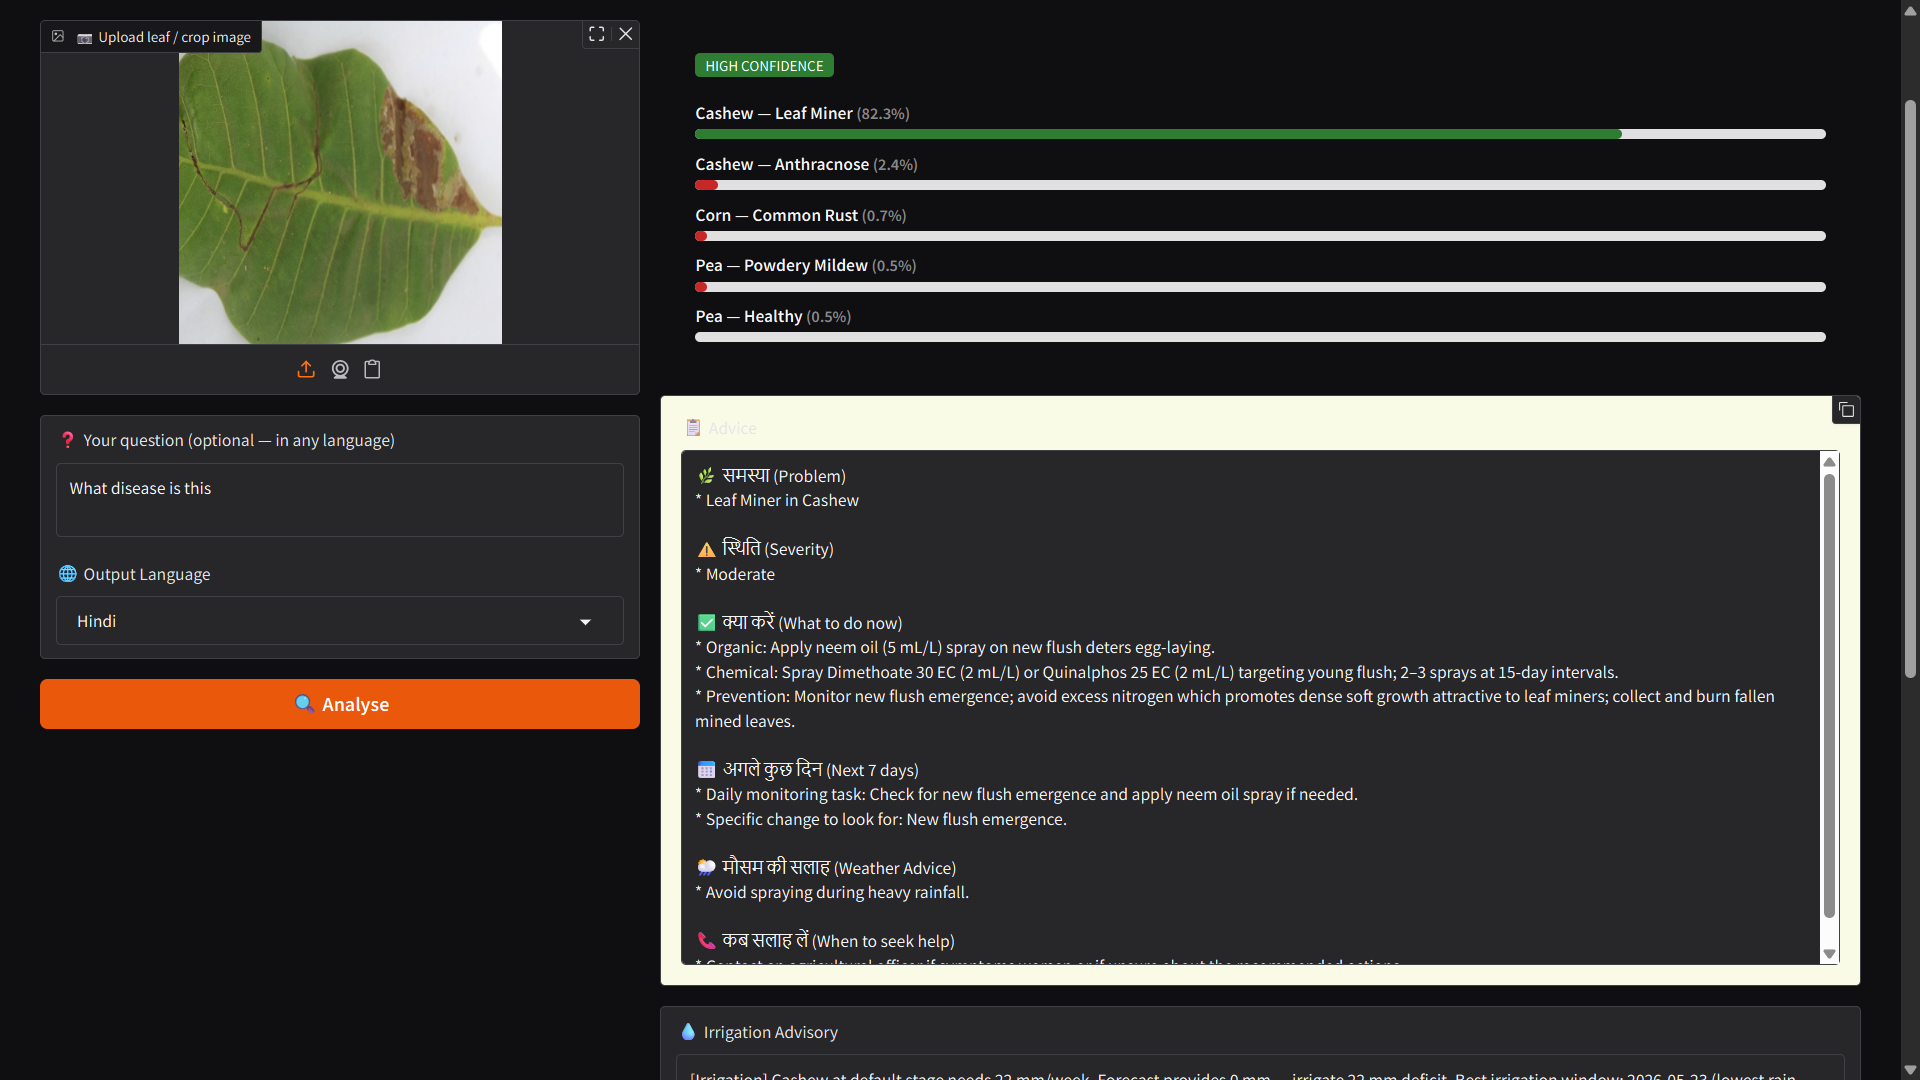